# Modelado y selección del predictor de género

Este notebook elige un clasificador para `main_genre`. No repite el EDA ni la preparación: usa el corte, los transformadores y las exclusiones del notebook 02.

La entrada de cada predicción es el string `chords` de una pista. La etiqueta es el género del artista en Spotify, copiado a esa pista. El artista no entra como variable. Una predicción responde qué género de catálogo corresponde a una progresión cuyo artista no estuvo en el entrenamiento.

Las celdas están escritas para ejecutarse en orden desde un kernel reiniciado. Aquí no hay salidas guardadas.


## 1. Objetivo, métrica y protocolo

**Tipo.** Clasificación de 12 clases: alternative, country, electronic, jazz, metal, pop, pop rock, punk, rap, reggae, rock y soul.

**Métrica principal.** Macro-F1. Promedia el F1 de las doce clases, así que equivocar reggae pesa lo mismo que equivocar pop. Accuracy no decide: pop es cerca del 24 % de las filas y un clasificador constante en pop ya rondaría ese valor con un macro-F1 cercano a cero.

**Métricas secundarias.** Accuracy, para comparar contra el piso de la clase mayoritaria. F1 por clase y matriz de confusión, solo en la evaluación final, para ver si los errores caen dentro de pop, rock, pop rock, alternative y punk. Esas cinco familias comparten lenguaje armónico en el EDA. No se usan para elegir el modelo.

**Corte externo.** El mismo que el notebook 02: holdout congelado por `data/make_holdout.py` (filas con `main_genre`, agrupado por `artist_id`, 20 % de los artistas, semilla 2026, hash en `data/holdout_manifest.json`). El corte anterior (semilla 42) quedó como desarrollo: sus artistas están ahora en el pool de validación cruzada. Además, las filas de desarrollo cuyo `chords` exacto aparece en el holdout se descartan (`src/chorddata.py`), para que una misma progresión no quede a ambos lados. Un artista viaja entero a un solo lado. El holdout no se inspecciona y no vuelve a usarse hasta la última evaluación.

**Validación.** `StratifiedGroupKFold` de 3 folds, con barajado y semilla 42, solo sobre train. Es el equivalente agrupado que pide la asignación: varias filas por artista, y además conserva las clases raras en cada fold. Hace falta que cada artista tenga una sola etiqueta y que cada clase tenga al menos tres artistas. Esos dos supuestos se comprueban antes de ajustar nada.

Tres folds, no cinco. En el notebook 02, ajustar una vez los ocho vocabularios llevó unos 22 minutos. Cada fold vuelve a aprender el vocabulario solo con sus artistas. Cinco folds casi duplicarían ese costo antes de comparar modelos.

**Misma partición.** Los índices se materializan una vez. Representaciones, clasificadores y trials de Optuna leen esos índices.

**Fuga.** El vocabulario, el imputador y el escalador se ajustan dentro de cada fold. `min_df` 5 y el tope de 5.000 se mantienen fijos: moverlos obligaría a rehacer el vocabulario en cada trial. El test no entra en esa elección, ni en la del modelo, ni en la de los hiperparámetros.


In [1]:
from __future__ import annotations

import sys
from pathlib import Path

import numpy as np
import pandas as pd

YEAR_MIN = 1899
YEAR_MAX = 2023

REQUIRED_COLUMNS = [
    "id",
    "chords",
    "release_date",
    "genres",
    "decade",
    "rock_genre",
    "artist_id",
    "main_genre",
    "spotify_song_id",
    "spotify_artist_id",
]

# Los CSV y el modulo se buscan desde la raiz del repo o desde notebooks/.
if (Path("data") / "chordonomicon_v2_part_0.csv").exists():
    DATA_DIR = Path("data")
elif (Path("..") / "data" / "chordonomicon_v2_part_0.csv").exists():
    DATA_DIR = Path("..") / "data"
else:
    raise FileNotFoundError(
        "No están los CSV chordonomicon_v2_part_*.csv en data/ ni en ../data/."
    )

SRC_DIR = Path("src") if (Path("src") / "chordmodel.py").exists() else Path("..") / "src"
if not (SRC_DIR / "chordmodel.py").exists():
    raise FileNotFoundError("No esta src/chordmodel.py en src/ ni en ../src/.")
sys.path.insert(0, str(SRC_DIR.resolve()))

from chorddata import dev_mask, holdout_mask, load_holdout_spec, load_shards
from chordmodel import (
    FEATURE_COLUMNS,
    LABELS,
    MAIN_GENRES,
    NGRAM_MAX_FEATURES,
    NGRAM_MIN_DF,
    NGRAM_ORDERS,
    SEED,
    assert_unfitted,
    build_estimator,
    make_aggregate_preprocessor,
    make_ngram_transformer,
    make_pipeline,
)

print("DATA_DIR =", DATA_DIR.resolve())
print("SRC_DIR  =", SRC_DIR.resolve())
print("semilla =", SEED, "| holdout: data/holdout_manifest.json")
print(
    "n-gramas: órdenes",
    NGRAM_ORDERS,
    "| min_df =",
    NGRAM_MIN_DF,
    "| tope =",
    NGRAM_MAX_FEATURES,
)


DATA_DIR = C:\Users\DELL\OneDrive\Desktop\Semestre 1-2026\Machine Learning\projects\music_Chordonomicon_genre_predictor\data
semilla = 42 | fracción de artistas en test = 0.2
n-gramas: órdenes (1, 2, 3, 4) | min_df = 5 | tope = 5000


In [2]:
import gc
import time

import matplotlib.pyplot as plt
import optuna
from sklearn.base import clone
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.model_selection import StratifiedGroupKFold

optuna.logging.set_verbosity(optuna.logging.WARNING)

N_SPLITS = 3
N_TRIALS = 20

PARAMS_NB = {"alpha": 1.0}
PARAMS_SGD = {"alpha": 1e-4, "penalty": "l2", "class_weight": "balanced"}
PARAMS_SVC = {"C": 1.0}

CONFIG_NB = "alpha=1.0"
CONFIG_SGD = "log_loss, penalty=l2, alpha=1e-4, class_weight=balanced"
CONFIG_SVC = "C=1.0, class_weight=balanced, dual=False, max_iter=100"
CONFIG_DUMMY = "strategy=most_frequent"

print("Clases:", LABELS)
print("Folds:", N_SPLITS, "| trials de Optuna:", N_TRIALS)


Clases: ['alternative', 'country', 'electronic', 'jazz', 'metal', 'pop', 'pop rock', 'punk', 'rap', 'reggae', 'rock', 'soul']
Folds: 3 | trials de Optuna: 20


## 2. Carga y corte

Los siete CSV se concatenan y se validan como en el notebook 02. El corte de almacenamiento no es el corte de modelado. Después se aparta el 20 % de los artistas. La tabla de clases describe solo train; no modifica el pipeline. Del holdout solo se muestran tamaños, no etiquetas.


In [3]:
def validate_raw(df: pd.DataFrame) -> None:
    missing = [column for column in REQUIRED_COLUMNS if column not in df.columns]
    if missing:
        raise ValueError(f"Faltan columnas requeridas: {missing}")

    duplicated_ids = int(df["id"].duplicated().sum())
    if duplicated_ids:
        raise ValueError(f"Hay {duplicated_ids:,} id duplicados. Cada fila debe ser una pista.")

    if df["chords"].isna().any():
        raise ValueError(
            "chords tiene valores ausentes. En el EDA esa columna está completa y es la entrada del modelo."
        )

    present = set(df["main_genre"].dropna().unique())
    unexpected = sorted(present - MAIN_GENRES)
    if unexpected:
        raise ValueError(f"main_genre tiene clases fuera de las 12 esperadas: {unexpected}")
    absent = sorted(MAIN_GENRES - present)
    if absent:
        raise ValueError(f"main_genre no contiene estas clases esperadas: {absent}")

    dated = df["release_date"].notna()
    years = pd.to_numeric(
        df.loc[dated, "release_date"].astype("string").str.slice(0, 4),
        errors="coerce",
    )
    unreadable = int(years.isna().sum())
    if unreadable:
        raise ValueError(
            f"{unreadable:,} release_date no empiezan por un año de cuatro dígitos."
        )
    out_of_range = (years < YEAR_MIN) | (years > YEAR_MAX)
    n_out = int(out_of_range.sum())
    if n_out:
        sample = years.loc[out_of_range].head(5).tolist()
        raise ValueError(
            f"{n_out:,} fechas tienen año fuera de {YEAR_MIN}–{YEAR_MAX}. Ejemplos: {sample}"
        )

    numeric = df.select_dtypes(include="number")
    n_inf = int(np.isinf(numeric.to_numpy(dtype=float)).sum())
    if n_inf:
        raise ValueError(f"Hay {n_inf:,} valores infinitos en columnas numéricas.")

    print("Validación superada.")
    print(f"Filas: {len(df):,} | columnas: {list(df.columns)}")
    print(f"id únicos: {df['id'].nunique():,}")
    print(f"Con main_genre: {int(df['main_genre'].notna().sum()):,}")
    print(f"Años fechados dentro de {YEAR_MIN}–{YEAR_MAX}: {int(dated.sum()):,}")


raw = load_shards(DATA_DIR)
validate_raw(raw)


chordonomicon_v2_part_0.csv: 100,000 filas
chordonomicon_v2_part_1.csv: 100,000 filas
chordonomicon_v2_part_2.csv: 100,000 filas
chordonomicon_v2_part_3.csv: 100,000 filas
chordonomicon_v2_part_4.csv: 100,000 filas
chordonomicon_v2_part_5.csv: 100,000 filas
chordonomicon_v2_part_6.csv: 79,807 filas
Validación superada.
Filas: 679,807 | columnas: ['id', 'chords', 'release_date', 'genres', 'decade', 'rock_genre', 'artist_id', 'main_genre', 'spotify_song_id', 'spotify_artist_id']
id únicos: 679,807
Con main_genre: 352,111
Años fechados dentro de 1899–2023: 422,181


El split agrupa por artista. No se estratifica por fila: partir un artista pondría su etiqueta en los dos lados. Las cuotas del holdout pueden diferir de las de train porque un artista entero viaja junto, pero no se miran: las etiquetas del holdout no se inspeccionan hasta la evaluación final. Tras el corte solo queda `test_idx` (posiciones). `raw`, `target` y `supervised` se borran, y `X_test` y `y_test` se arman en la celda final, después de ajustar el modelo. La tabla de train no se usa para elegir representación, modelo ni hiperparámetros.


In [ ]:
# Corte train / holdout. No elige modelo. Las etiquetas del holdout no se leen aqui.
supervised = raw.loc[raw["main_genre"].notna()].copy()
missing_artist = int(supervised["artist_id"].isna().sum())
if missing_artist:
    raise ValueError(
        f"{missing_artist:,} filas tienen main_genre y no tienen artist_id. "
        "El split agrupado no puede asignarlas sin romper el grupo."
    )

print(f"Universo supervisado: {len(supervised):,} filas, {supervised['artist_id'].nunique():,} artistas")

features = supervised.drop(columns=["main_genre"])
target = supervised["main_genre"]
groups = supervised["artist_id"]

# Corte definido en src/chorddata.py con el holdout congelado de data/make_holdout.py.
holdout_artists, manifest = load_holdout_spec(DATA_DIR)
in_holdout = holdout_mask(supervised, holdout_artists)
in_dev = dev_mask(raw, holdout_artists)[raw["main_genre"].notna().to_numpy()]
train_idx = np.flatnonzero(in_dev)
test_idx = np.flatnonzero(in_holdout)
if (
    len(train_idx) != manifest["n_rows_dev_labeled"]
    or len(test_idx) != manifest["n_rows_holdout"]
):
    raise ValueError("Los tamaños del corte no coinciden con el manifiesto.")
n_duplicates = int((~in_holdout & ~in_dev).sum())
print(f"Filas de dev descartadas por repetir un chords del holdout: {n_duplicates:,}")

X_train = features.iloc[train_idx].copy()
y_train = target.iloc[train_idx].copy()

# Del holdout solo se guardan posiciones (test_idx). X_test y y_test se arman
# en la celda de evaluacion final, despues de ajustar el modelo.
holdout_ids = supervised["id"].iloc[test_idx]
holdout_groups = groups.iloc[test_idx]
shared_artists = set(X_train["artist_id"].astype(str)).intersection(holdout_groups.astype(str))
shared_ids = set(X_train["id"]).intersection(holdout_ids)
if shared_artists:
    raise ValueError(f"El split comparte {len(shared_artists):,} artist_id entre train y holdout.")
if shared_ids:
    raise ValueError(f"El split comparte {len(shared_ids):,} id entre train y holdout.")

print(f"Train:   {len(X_train):,} filas | {X_train['artist_id'].nunique():,} artistas")
print(f"Holdout: {len(test_idx):,} filas | {holdout_groups.nunique():,} artistas (sin etiquetas en memoria)")
print("Artistas en común: 0 | id en común: 0")

# Solo se describe train. Las etiquetas del holdout no se miran ni se cuentan.
class_counts = pd.DataFrame({"train": y_train.value_counts()}).astype(int)
class_counts["train_share"] = class_counts["train"] / class_counts["train"].sum()
class_counts = class_counts.sort_values("train", ascending=False)

# Soltar todo lo que contiene etiquetas del holdout. Tambien libera memoria.
del raw, supervised, features, target, groups, holdout_ids, holdout_groups
gc.collect()
class_counts


## 3. Pipeline del modelo

Los transformadores, la lectura de acordes y las fábricas de pipeline viven en `src/chordmodel.py`. Este notebook y el notebook 02 los importan de ahí, y el pipeline guardado en `model.joblib` los referencia por ese módulo, así que se puede cargar fuera del notebook.

Los pipelines no se recuperan ajustados: las fábricas entregan estimadores sin fit y cada fold ajusta el suyo. Un pipeline ajustado con todo train no sirve para comparar folds.

Hay dos familias, y no se concatenan.

El agregado produce 13 columnas. Doce van a imputación por mediana y `StandardScaler`. `has_structure` se imputa con la moda y se queda en 0/1. `n_chords` y `log1p_n_chords` conviven; las proporciones de calidad suman uno. La regularización L2 de los lineales absorbe esa colinealidad. No se quita una columna fuera de la validación.

Los n-gramas son conteos dispersos, en grafía absoluta o en grados, de orden 1 a 4. No se escalan: el escalado densificaría la matriz. El vocabulario de cada fold sale solo de los artistas de ese fold.

`ComplementNB` solo entra en los n-gramas. El agregado escalado tiene negativos, y este modelo exige conteos no negativos. `SGDClassifier` y `LinearSVC` sí se miden también sobre las 13 columnas, como control de esa representación.


## 4. Fábricas sin ajustar

Cada llamada construye objetos nuevos. Un pipeline ajustado no se reutiliza en otro fold ni en otro modelo. La caché de un fold ajusta el transformador solo con las filas de ajuste de ese fold y transforma las de validación. Los clasificadores entrenan después, sobre esas matrices, así el vocabulario no se repite por cada modelo ni por cada trial.

La regla de desempate es la misma en todo el notebook. Gana la media de macro-F1 más alta. Si la diferencia con el siguiente no supera la desviación del líder entre folds, se queda la opción más simple: menos columnas entre representaciones, menos complejidad entre modelos. La complejidad crece en este orden: ComplementNB, LinearSVC, SGD inicial, SGD ajustado.


In [7]:
def cache_folds(transformer, frame, target, splits):
    assert_unfitted(transformer)
    folds = []
    started = time.perf_counter()
    for train_pos, val_pos in splits:
        step = clone(transformer)
        Z_fit = step.fit_transform(frame.iloc[train_pos])
        Z_val = step.transform(frame.iloc[val_pos])
        if Z_fit.shape[0] != len(train_pos) or Z_val.shape[0] != len(val_pos):
            raise ValueError("El transformador cambió el número de filas.")
        if Z_fit.shape[1] == 0:
            raise ValueError("Un fold produjo cero columnas.")
        folds.append(
            {
                "Z_fit": Z_fit,
                "y_fit": target.iloc[train_pos].to_numpy(),
                "Z_val": Z_val,
                "y_val": target.iloc[val_pos].to_numpy(),
            }
        )
    assert_unfitted(transformer)
    return folds, time.perf_counter() - started


def evaluate_estimator(kind: str, params: dict, folds) -> dict:
    f1_folds = []
    accuracies = []
    fit_times = []
    for fold in folds:
        model = build_estimator(kind, params)
        started = time.perf_counter()
        model.fit(fold["Z_fit"], fold["y_fit"])
        fit_times.append(time.perf_counter() - started)
        predicted = model.predict(fold["Z_val"])
        f1_folds.append(
            f1_score(
                fold["y_val"],
                predicted,
                average="macro",
                labels=LABELS,
                zero_division=0,
            )
        )
        accuracies.append(accuracy_score(fold["y_val"], predicted))
    f1_values = np.asarray(f1_folds, dtype=float)
    return {
        "f1_media": float(f1_values.mean()),
        "f1_desv": float(f1_values.std(ddof=1)),
        "accuracy_media": float(np.mean(accuracies)),
        "tiempo_ajuste_s": float(np.mean(fit_times)),
        "f1_folds": [float(value) for value in f1_values],
    }


def nueva_fila(
    representacion,
    modelo,
    configuracion,
    kind,
    params,
    complejidad,
    n_features,
    tiempo_cache_s,
    metrics,
) -> dict:
    row = {
        "representacion": representacion,
        "modelo": modelo,
        "configuracion": configuracion,
        "kind": kind,
        "params": params,
        "complejidad": complejidad,
        "n_features": n_features,
        "tiempo_cache_s": tiempo_cache_s,
    }
    row.update(metrics)
    return row


def elegir_por_margen(rows: list[dict], simplicity_key: str):
    ranked = sorted(
        rows,
        key=lambda row: (
            -row["f1_media"],
            row[simplicity_key],
            row["f1_desv"],
            row["tiempo_ajuste_s"],
        ),
    )
    best = ranked[0]
    second = ranked[1] if len(ranked) > 1 else ranked[0]
    margin = best["f1_media"] - second["f1_media"]
    if margin <= best["f1_desv"]:
        chosen = min(
            (best, second),
            key=lambda row: (
                row[simplicity_key],
                row["f1_desv"],
                row["tiempo_ajuste_s"],
                -row["f1_media"],
            ),
        )
    else:
        chosen = best
    return best, second, chosen


def explicar_margen(best, second, chosen, name_key: str) -> None:
    margin = best["f1_media"] - second["f1_media"]
    print(
        f"Líder: {best[name_key]} / {best['modelo']} — "
        f"macro-F1 {best['f1_media']:.4f} ± {best['f1_desv']:.4f}"
    )
    print(
        f"Siguiente: {second[name_key]} / {second['modelo']} — "
        f"macro-F1 {second['f1_media']:.4f} ± {second['f1_desv']:.4f}"
    )
    print(f"Diferencia {margin:.4f}. Desviación del líder {best['f1_desv']:.4f}.")
    if margin > best["f1_desv"] and chosen is best:
        print(f"La diferencia supera la desviación. Queda {chosen[name_key]} / {chosen['modelo']}.")
    else:
        print(
            "La diferencia no supera la desviación entre folds. "
            f"Queda la opción más simple: {chosen[name_key]} / {chosen['modelo']}."
        )
    print("Folds del elegido:", [round(value, 4) for value in chosen["f1_folds"]])


def as_table(rows: list[dict], extra=()):
    columns = [
        ("representacion", "Representación"),
        ("modelo", "Modelo"),
        ("configuracion", "Configuración"),
        ("f1_media", "Media"),
        ("f1_desv", "Desv."),
        ("tiempo_ajuste_s", "Tiempo"),
        ("accuracy_media", "Accuracy"),
        ("n_features", "Columnas"),
        *extra,
    ]
    frame = pd.DataFrame(rows)
    show = pd.DataFrame({label: frame[key] for key, label in columns})
    for column in ("Media", "Desv.", "Accuracy"):
        show[column] = show[column].map(lambda value: round(float(value), 4))
    for column in ("Tiempo", "Tiempo caché"):
        if column in show.columns:
            show[column] = show[column].map(lambda value: round(float(value), 1))
    return show.sort_values(["Media", "Desv."], ascending=[False, True]).reset_index(drop=True)


def describe_sgd(params: dict) -> str:
    weight = "None" if params["class_weight"] is None else params["class_weight"]
    text = (
        f"log_loss, penalty={params['penalty']}, "
        f"alpha={params['alpha']:.6g}, class_weight={weight}"
    )
    if params["penalty"] == "elasticnet":
        text += f", l1_ratio={params['l1_ratio']:.3f}"
    return text


print("Fábricas listas. Ningún estimador se ha ajustado.")


Fábricas listas. Ningún estimador se ha ajustado.


## 5. Validación cruzada

Los tres folds se fijan antes de los modelos. El guardia comprueba la etiqueta única por artista y, como mínimo, tres artistas por clase. Después se comprueba que ningún artista aparezca en el ajuste y en la validación del mismo fold.


In [8]:
artist_labels = (
    pd.DataFrame(
        {
            "artist_id": X_train["artist_id"].to_numpy(),
            "main_genre": y_train.to_numpy(),
        }
    )
    .groupby("artist_id", sort=False)["main_genre"]
    .nunique()
)
mixed = int((artist_labels > 1).sum())
if mixed:
    raise ValueError(
        f"{mixed} artistas de train tienen más de un main_genre. "
        "StratifiedGroupKFold dejaría de estar definido."
    )

artists_per_class = (
    pd.DataFrame(
        {
            "artist_id": X_train["artist_id"].to_numpy(),
            "main_genre": y_train.to_numpy(),
        }
    )
    .drop_duplicates()
    .groupby("main_genre")["artist_id"]
    .nunique()
)
short = artists_per_class[artists_per_class < N_SPLITS]
if len(short):
    raise ValueError(
        f"Estas clases tienen menos de {N_SPLITS} artistas en train: "
        f"{short.to_dict()}."
    )

cv = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
cv_splits = list(cv.split(X_train, y_train, X_train["artist_id"].to_numpy()))
if len(cv_splits) != N_SPLITS:
    raise ValueError(f"Se esperaban {N_SPLITS} folds y salieron {len(cv_splits)}.")

for fold_id, (train_pos, val_pos) in enumerate(cv_splits, start=1):
    if len(set(train_pos).intersection(val_pos)):
        raise ValueError(f"El fold {fold_id} repite filas.")
    train_artists = set(X_train.iloc[train_pos]["artist_id"])
    val_artists = set(X_train.iloc[val_pos]["artist_id"])
    shared = train_artists.intersection(val_artists)
    if shared:
        raise ValueError(f"El fold {fold_id} comparte {len(shared)} artistas.")
    print(
        f"Fold {fold_id}: ajuste {len(train_pos):,} filas, "
        f"{len(train_artists):,} artistas | "
        f"validación {len(val_pos):,} filas, {len(val_artists):,} artistas"
    )

print("Artistas por clase en train:")
print(artists_per_class.sort_values(ascending=False).to_string())
print("Los índices quedan fijos para el resto del notebook.")


Fold 1: ajuste 194,279 filas, 20,299 artistas | validación 88,868 filas, 10,146 artistas
Fold 2: ajuste 190,506 filas, 20,296 artistas | validación 92,641 filas, 10,149 artistas
Fold 3: ajuste 181,509 filas, 20,295 artistas | validación 101,638 filas, 10,150 artistas
Artistas por clase en train:
main_genre
pop            8559
alternative    5033
rock           4334
country        2809
rap            2256
pop rock       1624
punk           1342
metal          1106
jazz           1087
soul           1060
electronic      751
reggae          484
Los índices quedan fijos para el resto del notebook.


## 6. Baseline y candidatos

El piso es `DummyClassifier(strategy="most_frequent")`: siempre predice la clase más frecuente del fold, que en este corte es pop. Ignora los acordes. Su macro-F1 es el número que los demás tienen que superar fuera de la variación entre folds.

Los tres modelos son lineales y distintos. Los tres leen la matriz dispersa de conteos. Ninguno ve `artist_id`.

**ComplementNB.** Estima qué n-gramas son frecuentes en cada género y corrige el sesgo hacia las clases grandes. Necesita conteos no negativos, así que va sobre los n-gramas y no sobre el agregado escalado. Es barato y es el que criba las ocho representaciones. Su límite es la independencia entre n-gramas: una pareja de acordes solo cuenta si el orden del n-grama ya la incluyó. Configuración inicial: `alpha=1.0`.

**SGDClassifier con `loss="log_loss"`.** Es una logística entrenada por lotes, con `class_weight="balanced"`. Cabe en 283 mil filas y 5.000 columnas, y cada trial cambia `alpha`, la penalización y el peso de clase sin rehacer el vocabulario. Se mueve más entre corridas que una logística cerrada; la semilla 42 fija el orden de las filas. Configuración inicial: `penalty="l2"`, `alpha=1e-4`, `class_weight="balanced"`, `max_iter=1000`.

**LinearSVC.** Doce clasificadores de margen, uno por género, en forma primal (`dual=False`) porque hay muchas más filas que columnas. El macro-F1 no necesita probabilidades. No se calibra: la calibración multiplicaría el costo y la matriz de confusión se lee con la clase asignada. Configuración inicial: `C=1.0`, `class_weight="balanced"`, `dual=False`, `max_iter=100`. Con 1000 iteraciones no convergía sobre los n-gramas sin escalar y tardaba horas; 100 acota el costo y deja una advertencia de convergencia.

Pasan a Optuna solo el SGD. ComplementNB tiene un único parámetro útil ya fijado en la criba, y LinearSVC se queda en su C inicial como control de margen. El SGD es el candidato cuyo resultado inicial puede deberse a `alpha` y a la penalización. El ajuste se acepta solo si la mejora supera la desviación del SGD inicial.


## 7. Comparación inicial

Primero, ComplementNB en los ocho n-gramas, con los mismos folds. El vocabulario de cada representación se ajusta y se suelta antes de pasar a la siguiente, para no guardar ocho matrices a la vez. La criba elige el n-grama. No elige todavía el clasificador final.

En paralelo, el agregado de 13 columnas se evalúa con el SGD inicial y con LinearSVC. Es el control que el notebook 02 dejó abierto. Esas dos filas no compiten dentro de la criba de n-gramas, porque el modelo no es el mismo. Entran al final, y solo reemplazan al ganador de los n-gramas si lo superan por más que la desviación de ambos.

La columna Tiempo es el ajuste del clasificador. El tiempo de la caché, que es el del vocabulario, se imprime aparte y también queda en la tabla de representaciones.


In [9]:
screen_rows = []
ngram_names = [
    f"{alphabet}_{order}"
    for alphabet in ("absolute", "degree")
    for order in NGRAM_ORDERS
]
for name in ngram_names:
    print(f"Caché y ComplementNB: {name}")
    folds, cache_s = cache_folds(
        make_ngram_transformer(name), X_train, y_train, cv_splits
    )
    metrics = evaluate_estimator("complement_nb", PARAMS_NB, folds)
    n_features = int(folds[0]["Z_fit"].shape[1])
    screen_rows.append(
        nueva_fila(
            name,
            "ComplementNB",
            CONFIG_NB,
            "complement_nb",
            PARAMS_NB,
            0,
            n_features,
            cache_s,
            metrics,
        )
    )
    print(
        f"{name}: macro-F1 {metrics['f1_media']:.4f} ± {metrics['f1_desv']:.4f}, "
        f"caché {cache_s:.1f} s, columnas {n_features}"
    )
    del folds

print("Caché del agregado")
aggregate_folds, aggregate_cache_s = cache_folds(
    make_aggregate_preprocessor(), X_train, y_train, cv_splits
)
aggregate_n_features = int(aggregate_folds[0]["Z_fit"].shape[1])
if aggregate_n_features != len(FEATURE_COLUMNS):
    raise ValueError(
        f"El agregado produjo {aggregate_n_features} columnas "
        f"y se esperaban {len(FEATURE_COLUMNS)}."
    )
aggregate_specs = [
    ("sgd", "SGDClassifier", CONFIG_SGD, PARAMS_SGD, 2),
    ("linear_svc", "LinearSVC", CONFIG_SVC, PARAMS_SVC, 1),
]
aggregate_rows = []
for kind, modelo, config, params, complejidad in aggregate_specs:
    print(f"Agregado: {modelo}")
    metrics = evaluate_estimator(kind, params, aggregate_folds)
    aggregate_rows.append(
        nueva_fila(
            "aggregate",
            modelo,
            config,
            kind,
            params,
            complejidad,
            aggregate_n_features,
            aggregate_cache_s,
            metrics,
        )
    )
del aggregate_folds
gc.collect()

best_ngram, second_ngram, ngram_choice = elegir_por_margen(screen_rows, "n_features")
explicar_margen(best_ngram, second_ngram, ngram_choice, "representacion")
_, _, aggregate_choice = elegir_por_margen(aggregate_rows, "complejidad")
print(
    "Control agregado:",
    aggregate_choice["modelo"],
    f"{aggregate_choice['f1_media']:.4f} ± {aggregate_choice['f1_desv']:.4f}",
)
print(
    "Los tres clasificadores se comparan en",
    ngram_choice["representacion"],
    ". ComplementNB no admite el agregado escalado.",
)
as_table(
    screen_rows + aggregate_rows,
    extra=(("tiempo_cache_s", "Tiempo caché"),),
)


Caché y ComplementNB: absolute_1
absolute_1: macro-F1 0.1145 ± 0.0044, caché 56.8 s, columnas 1294
Caché y ComplementNB: absolute_2
absolute_2: macro-F1 0.1396 ± 0.0034, caché 66.8 s, columnas 5000
Caché y ComplementNB: absolute_3
absolute_3: macro-F1 0.1426 ± 0.0033, caché 123.2 s, columnas 5000
Caché y ComplementNB: absolute_4
absolute_4: macro-F1 0.1308 ± 0.0014, caché 140.5 s, columnas 5000
Caché y ComplementNB: degree_1
degree_1: macro-F1 0.0882 ± 0.0014, caché 692.5 s, columnas 42
Caché y ComplementNB: degree_2
degree_2: macro-F1 0.1209 ± 0.0027, caché 478.9 s, columnas 1183
Caché y ComplementNB: degree_3
degree_3: macro-F1 0.1411 ± 0.0019, caché 808.5 s, columnas 5000
Caché y ComplementNB: degree_4
degree_4: macro-F1 0.1445 ± 0.0010, caché 658.6 s, columnas 5000
Caché del agregado
Agregado: SGDClassifier
Agregado: LinearSVC
Líder: degree_4 / ComplementNB — macro-F1 0.1445 ± 0.0010
Siguiente: absolute_3 / ComplementNB — macro-F1 0.1426 ± 0.0033
Diferencia 0.0018. Desviación del l

,Representación,Modelo,Configuración,Media,Desv.,Tiempo,Accuracy,Columnas,Tiempo caché
0,degree_4,ComplementNB,alpha=1.0,0.1445,0.0010,0.5,0.2673,5000,658.6
1,absolute_3,ComplementNB,alpha=1.0,0.1426,0.0033,1.1,0.2632,5000,123.2
2,degree_3,ComplementNB,alpha=1.0,0.1411,0.0019,0.8,0.2631,5000,808.5
3,absolute_2,ComplementNB,alpha=1.0,0.1396,0.0034,0.5,0.2503,5000,66.8
4,absolute_4,ComplementNB,alpha=1.0,0.1308,0.0014,0.5,0.2516,5000,140.5
5,degree_2,ComplementNB,alpha=1.0,0.1209,0.0027,1.0,0.2441,1183,478.9
6,aggregate,LinearSVC,"C=1.0, class_weight=balanced, dual=False, max_...",0.1149,0.0049,13.8,0.1816,13,148.8
7,absolute_1,ComplementNB,alpha=1.0,0.1145,0.0044,0.4,0.2237,1294,56.8
8,aggregate,SGDClassifier,"log_loss, penalty=l2, alpha=1e-4, class_weight...",0.1106,0.0051,6.6,0.1876,13,148.8
9,degree_1,ComplementNB,alpha=1.0,0.0882,0.0014,1.2,0.2141,42,692.5


La celda anterior imprime el líder, el siguiente y la diferencia contra la desviación del líder. Esa frase es la elección del n-grama. Una diferencia menor que la desviación no se lee como superioridad: por eso el vocabulario más chico de esos dos se queda con el puesto.

El tiempo de caché es el costo de reaprender el vocabulario tres veces. El tiempo de la tabla, en la columna Tiempo, es solo el del clasificador. Comparar representaciones por el segundo y olvidar el primero escondería el costo real del orden alto.

## 8. Los tres modelos en el n-grama elegido

Se rehace la caché de esa representación con los mismos índices. Sobre esas matrices entrenan el dummy, ComplementNB, el SGD inicial y LinearSVC. La tabla es la configuración inicial. La selección espera al ajuste del SGD.


In [10]:
print("Rehaciendo la caché de", ngram_choice["representacion"])
winner_folds, winner_cache_s = cache_folds(
    make_ngram_transformer(ngram_choice["representacion"]),
    X_train,
    y_train,
    cv_splits,
)
winner_features = int(winner_folds[0]["Z_fit"].shape[1])
model_specs = [
    ("dummy", "DummyClassifier", CONFIG_DUMMY, {}, -1),
    ("complement_nb", "ComplementNB", CONFIG_NB, PARAMS_NB, 0),
    ("sgd", "SGDClassifier", CONFIG_SGD, PARAMS_SGD, 2),
    ("linear_svc", "LinearSVC", CONFIG_SVC, PARAMS_SVC, 1),
]
model_rows = []
for kind, modelo, config, params, complejidad in model_specs:
    print("Ajustando", modelo)
    metrics = evaluate_estimator(kind, params, winner_folds)
    model_rows.append(
        nueva_fila(
            ngram_choice["representacion"],
            modelo,
            config,
            kind,
            params,
            complejidad,
            winner_features,
            winner_cache_s,
            metrics,
        )
    )
    print(
        f"{modelo}: macro-F1 {metrics['f1_media']:.4f} ± {metrics['f1_desv']:.4f}, "
        f"ajuste {metrics['tiempo_ajuste_s']:.1f} s"
    )

print(f"Caché compartida por los cuatro: {winner_cache_s:.1f} s")
print("Esta tabla es la configuración inicial. Optuna todavía no ha corrido.")
as_table(model_rows)


Rehaciendo la caché de degree_4
Ajustando DummyClassifier
DummyClassifier: macro-F1 0.0325 ± 0.0010, ajuste 0.2 s
Ajustando ComplementNB
ComplementNB: macro-F1 0.1445 ± 0.0010, ajuste 0.7 s
Ajustando SGDClassifier
SGDClassifier: macro-F1 0.1262 ± 0.0042, ajuste 62.1 s
Ajustando LinearSVC


c:\Users\DELL\OneDrive\Desktop\Semestre 1-2026\Machine Learning\projects\music_Chordonomicon_genre_predictor\.venv\lib\site-packages\sklearn\svm\_base.py:1250: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
c:\Users\DELL\OneDrive\Desktop\Semestre 1-2026\Machine Learning\projects\music_Chordonomicon_genre_predictor\.venv\lib\site-packages\sklearn\svm\_base.py:1250: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
c:\Users\DELL\OneDrive\Desktop\Semestre 1-2026\Machine Learning\projects\music_Chordonomicon_genre_predictor\.venv\lib\site-packages\sklearn\svm\_base.py:1250: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


LinearSVC: macro-F1 0.1206 ± 0.0025, ajuste 1178.8 s
Caché compartida por los cuatro: 454.8 s
Esta tabla es la configuración inicial. Optuna todavía no ha corrido.


,Representación,Modelo,Configuración,Media,Desv.,Tiempo,Accuracy,Columnas
0,degree_4,ComplementNB,alpha=1.0,0.1445,0.0010,0.7,0.2673,5000
1,degree_4,SGDClassifier,"log_loss, penalty=l2, alpha=1e-4, class_weight...",0.1262,0.0042,62.1,0.1658,5000
2,degree_4,LinearSVC,"C=1.0, class_weight=balanced, dual=False, max_...",0.1206,0.0025,1178.8,0.1487,5000
3,degree_4,DummyClassifier,strategy=most_frequent,0.0325,0.0010,0.2,0.2425,5000


## 9. Optuna sobre SGD

La función objetivo es la media de macro-F1 en los tres folds ya cacheados. Se maximiza. El vocabulario no se vuelve a ajustar: los trials solo cambian el clasificador.

Espacio: `alpha` logarítmico entre `1e-6` y `1e-2`; penalización `l2`, `l1` o `elasticnet`; `l1_ratio` entre 0,05 y 0,95 solo si la penalización es elastic net; `class_weight` en `balanced` o ninguno. Presupuesto: 20 trials. Sampler: `TPESampler` con semilla 42. `max_iter` y `tol` se quedan en 1000 y `1e-3`.

`min_df` y el tope de 5.000 no entran al espacio. Cada valor nuevo reharía el vocabulario dentro de cada fold, y ese es el costo que esta máquina no puede multiplicar por 20. Con más recursos, el siguiente ensayo sería mover esos dos cortes solo en el alfabeto y el orden ya elegidos.

Después del estudio se vuelve a evaluar el mejor trial en los mismos folds, para tener media y desviación, y se compara con el SGD inicial. El número suelto del mejor trial no basta.


In [11]:
def objective(trial: optuna.Trial) -> float:
    penalty = trial.suggest_categorical("penalty", ["l2", "l1", "elasticnet"])
    params = {
        "alpha": trial.suggest_float("alpha", 1e-6, 1e-2, log=True),
        "penalty": penalty,
        "class_weight": {"balanced": "balanced", "none": None}[
            trial.suggest_categorical("class_weight", ["balanced", "none"])
        ],
    }
    if penalty == "elasticnet":
        params["l1_ratio"] = trial.suggest_float("l1_ratio", 0.05, 0.95)
    scores = []
    for fold in winner_folds:
        model = build_estimator("sgd", params)
        model.fit(fold["Z_fit"], fold["y_fit"])
        predicted = model.predict(fold["Z_val"])
        scores.append(
            f1_score(
                fold["y_val"],
                predicted,
                average="macro",
                labels=LABELS,
                zero_division=0,
            )
        )
    return float(np.mean(scores))


study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=SEED),
)
study_started = time.perf_counter()
study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=False)
study_seconds = time.perf_counter() - study_started

best_trial_params = study.best_params
tuned_params = {
    "alpha": best_trial_params["alpha"],
    "penalty": best_trial_params["penalty"],
    "class_weight": None if best_trial_params["class_weight"] == "none" else "balanced",
}
if tuned_params["penalty"] == "elasticnet":
    tuned_params["l1_ratio"] = best_trial_params["l1_ratio"]

tuned_metrics = evaluate_estimator("sgd", tuned_params, winner_folds)
tuned_row = nueva_fila(
    ngram_choice["representacion"],
    "SGDClassifier ajustado",
    describe_sgd(tuned_params),
    "sgd",
    tuned_params,
    3,
    winner_features,
    winner_cache_s,
    tuned_metrics,
)
initial_sgd = next(row for row in model_rows if row["modelo"] == "SGDClassifier")
tuning_gain = tuned_row["f1_media"] - initial_sgd["f1_media"]

print(f"Estudio: {len(study.trials)} trials en {study_seconds:.1f} s")
print(f"Mejor trial: {study.best_value:.4f}")
print(f"Reevaluación: {tuned_row['f1_media']:.4f} ± {tuned_row['f1_desv']:.4f}")
print(f"Parámetros: {tuned_row['configuracion']}")
print(
    f"SGD inicial: {initial_sgd['f1_media']:.4f} ± {initial_sgd['f1_desv']:.4f}. "
    f"Diferencia {tuning_gain:.4f}. Desviación del inicial {initial_sgd['f1_desv']:.4f}."
)
if tuning_gain > initial_sgd["f1_desv"]:
    print("El ajuste supera la variación entre folds del SGD inicial.")
else:
    print("El ajuste no supera la variación entre folds del SGD inicial.")

trial_table = (
    pd.DataFrame(
        [
            {"trial": trial.number, "macro_f1": trial.value, **trial.params}
            for trial in study.trials
            if trial.value is not None
        ]
    )
    .sort_values("macro_f1", ascending=False)
    .reset_index(drop=True)
)
trial_table["macro_f1"] = trial_table["macro_f1"].map(lambda value: round(float(value), 4))
trial_table


c:\Users\DELL\OneDrive\Desktop\Semestre 1-2026\Machine Learning\projects\music_Chordonomicon_genre_predictor\.venv\lib\site-packages\sklearn\linear_model\_stochastic_gradient.py:726: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
c:\Users\DELL\OneDrive\Desktop\Semestre 1-2026\Machine Learning\projects\music_Chordonomicon_genre_predictor\.venv\lib\site-packages\sklearn\linear_model\_stochastic_gradient.py:726: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
c:\Users\DELL\OneDrive\Desktop\Semestre 1-2026\Machine Learning\projects\music_Chordonomicon_genre_predictor\.venv\lib\site-packages\sklearn\linear_model\_stochastic_gradient.py:726: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
c:\Users\DELL\OneDrive\De

Estudio: 20 trials en 7886.8 s
Mejor trial: 0.1360
Reevaluación: 0.1360 ± 0.0065
Parámetros: log_loss, penalty=elasticnet, alpha=0.00866913, class_weight=balanced, l1_ratio=0.064
SGD inicial: 0.1262 ± 0.0042. Diferencia 0.0098. Desviación del inicial 0.0042.
El ajuste supera la variación entre folds del SGD inicial.


,trial,macro_f1,penalty,alpha,class_weight,l1_ratio
0,13,0.1360,elasticnet,0.008669,balanced,0.064431
1,11,0.1332,elasticnet,0.004420,balanced,0.084853
2,15,0.1315,l2,0.001263,balanced,NaN
3,5,0.1308,elasticnet,0.007287,balanced,0.137905
4,10,0.1297,elasticnet,0.001620,balanced,0.056793
5,14,0.1290,elasticnet,0.000435,balanced,0.075777
6,7,0.1289,l1,0.000120,balanced,NaN
7,0,0.1258,l1,0.000248,balanced,NaN
8,9,0.1244,l1,0.000020,balanced,NaN
9,18,0.1206,elasticnet,0.000032,none,0.284454


La reevaluación manda, no el valor suelto del mejor trial. Si la diferencia contra el SGD inicial no supera la desviación de ese inicial, el ajuste no demostró una mejora. Los dos siguen en la tabla de selección: la regla de margen puede quedarse con el inicial por ser más simple.

## 10. Selección y evaluación única

El pool es ComplementNB, SGD inicial, SGD ajustado y LinearSVC, todos en el n-grama elegido. El dummy se muestra como piso y no se elige. El agregado reemplaza a ese ganador solo si su media lo supera por más que la mayor de las dos desviaciones.

Después de esa decisión se suelta la caché, se construye un pipeline nuevo y se ajusta con todo train. El vocabulario de esa pasada ve todos los artistas de train, que es lo correcto para el modelo final, y no vio test. Hay una sola predicción. Repetir la celda en el mismo kernel se detiene a propósito.


In [12]:
# USA_TEST: evaluacion final unica. La elección ya está cerrada con los folds.
if globals().get("_test_evaluado", False):
    raise RuntimeError(
        "Test ya fue evaluado en esta sesión del kernel. "
        "Reinicia el kernel para no repetir la predicción."
    )

pool = [row for row in model_rows if row["kind"] != "dummy"] + [tuned_row]
best_model, second_model, chosen_row = elegir_por_margen(pool, "complejidad")
explicar_margen(best_model, second_model, chosen_row, "representacion")

aggregate_margin = aggregate_choice["f1_media"] - chosen_row["f1_media"]
aggregate_threshold = max(chosen_row["f1_desv"], aggregate_choice["f1_desv"])
print(
    f"Agregado {aggregate_choice['modelo']}: "
    f"{aggregate_choice['f1_media']:.4f} ± {aggregate_choice['f1_desv']:.4f}. "
    f"Diferencia {aggregate_margin:.4f}. Umbral {aggregate_threshold:.4f}."
)
if aggregate_margin > aggregate_threshold:
    print("El agregado supera ese umbral. El pipeline final usa las 13 columnas.")
    chosen_row = aggregate_choice
else:
    print("El agregado no supera ese umbral. El pipeline final usa los n-gramas.")

dummy_row = next(row for row in model_rows if row["kind"] == "dummy")
dummy_margin = chosen_row["f1_media"] - dummy_row["f1_media"]
print(
    "El dummy ignora la matriz. Con estos mismos folds su macro-F1 vale "
    "igual para el agregado y para los n-gramas."
)
print(
    f"Dummy: {dummy_row['f1_media']:.4f}. "
    f"Ventaja del elegido {dummy_margin:.4f}. "
    f"Desviación del elegido {chosen_row['f1_desv']:.4f}."
)
if dummy_margin <= chosen_row["f1_desv"]:
    print("Esa ventaja no supera la variación entre folds.")
else:
    print("Esa ventaja supera la variación entre folds.")

winner_folds = None
objective = None
gc.collect()

final_estimator = build_estimator(chosen_row["kind"], chosen_row["params"])
final_pipeline = make_pipeline(chosen_row["representacion"], final_estimator)
assert_unfitted(final_pipeline)

final_pipeline.fit(X_train, y_train)

# Primera y unica lectura de las etiquetas del holdout: el modelo ya esta ajustado.
_raw_final = load_shards(DATA_DIR)
_supervised_final = _raw_final.loc[_raw_final["main_genre"].notna()]
X_test = _supervised_final.drop(columns=["main_genre"]).iloc[test_idx].copy()
y_test = _supervised_final["main_genre"].iloc[test_idx].copy()
del _raw_final, _supervised_final
if len(X_test) != manifest["n_rows_holdout"]:
    raise ValueError("El holdout reconstruido no tiene el tamano del manifiesto.")
if set(X_test["artist_id"].astype(str)) != set(holdout_artists):
    raise ValueError("Los artistas del holdout reconstruido no coinciden con el manifiesto.")
if set(X_train["artist_id"].astype(str)).intersection(X_test["artist_id"].astype(str)):
    raise ValueError("Train y holdout comparten artistas.")

y_pred = final_pipeline.predict(X_test)
_test_evaluado = True

test_f1 = f1_score(y_test, y_pred, average="macro", labels=LABELS, zero_division=0)
test_accuracy = accuracy_score(y_test, y_pred)
print(
    f"Pipeline final: {chosen_row['representacion']} + {chosen_row['modelo']}. "
    f"Configuración: {chosen_row['configuracion']}."
)
print(
    f"Validación {chosen_row['f1_media']:.4f} ± {chosen_row['f1_desv']:.4f}. "
    f"Test: macro-F1 {test_f1:.4f}, accuracy {test_accuracy:.4f}."
)
print("Ese número de test no se usa para cambiar la elección.")


Líder: degree_4 / ComplementNB — macro-F1 0.1445 ± 0.0010
Siguiente: degree_4 / SGDClassifier ajustado — macro-F1 0.1360 ± 0.0065
Diferencia 0.0085. Desviación del líder 0.0010.
La diferencia supera la desviación. Queda degree_4 / ComplementNB.
Folds del elegido: [0.1455, 0.1435, 0.1444]
Agregado LinearSVC: 0.1149 ± 0.0049. Diferencia -0.0295. Umbral 0.0049.
El agregado no supera ese umbral. El pipeline final usa los n-gramas.
El dummy ignora la matriz. Con estos mismos folds su macro-F1 vale igual para el agregado y para los n-gramas.
Dummy: 0.0325. Ventaja del elegido 0.1119. Desviación del elegido 0.0010.
Esa ventaja supera la variación entre folds.
Pipeline final: degree_4 + ComplementNB. Configuración: alpha=1.0.
Validación 0.1445 ± 0.0010. Test: macro-F1 0.1449, accuracy 0.2759.
Ese número de test no se usa para cambiar la elección.


In [13]:
import joblib
joblib.dump(final_pipeline, "../model.joblib")


['../model.joblib']

## 11. Errores y limitaciones

La matriz y el F1 por clase describen la única predicción ya hecha. No eligen otro modelo.

La pregunta de lectura es cuántos errores se quedan dentro de pop, rock, pop rock, alternative y punk. El EDA midió que ese bloque comparte progresiones. Una fracción alta dentro del bloque es el techo de una etiqueta de artista leída desde una sola progresión. Una fracción alta fuera del bloque, por ejemplo jazz confundido con pop, diría que el modelo no está usando el contraste armónico que el EDA sí veía.

Limitaciones que no dependen del número que salga:

- La etiqueta es el género del catálogo del artista, no un género anotado pista por pista.
- Quedan 110 grupos, 267 filas, con la misma progresión en artistas distintos. El corte por artista no los separa todos.
- El EDA que motivó las features vio también las filas que ahora están en test. Este notebook no usa esas filas para elegir.
- Pop es cerca del 24 % y electronic cerca del 0,8 %. El macro-F1 trata igual esas clases; la matriz dice si las raras se están prediciendo.
- Tres folds dejan una desviación ancha. Una mejora menor que esa desviación no se declara.
- Los tres modelos son lineales. Un árbol sobre las 13 columnas, o un orden de n-grama distinto para cada modelo, queda fuera de este presupuesto.
- `min_df` y el tope de 5.000 no se buscaron.


F1 por clase, de peor a mejor:
             precision  recall  f1-score  support
electronic      0.0000  0.0000    0.0000      593
jazz            0.1232  0.0130    0.0236     1305
soul            0.0780  0.0185    0.0299     1463
pop rock        0.1449  0.0277    0.0465     7882
reggae          0.0651  0.0490    0.0559      572
punk            0.1680  0.0737    0.1025     3134
metal           0.0979  0.1462    0.1172     2155
rap             0.1131  0.1354    0.1232     2275
alternative     0.2321  0.1895    0.2087     9909
rock            0.2791  0.2524    0.2651    12205
pop             0.3472  0.4161    0.3785    16489
country         0.2982  0.5522    0.3873    10982
Errores fuera de la diagonal: 49,936
Errores dentro de pop / rock / pop rock / alternative / punk: 19,707 (39.5%)
Confusiones más frecuentes (real → predicho):
  3906  pop → country
  3344  rock → country
  2656  alternative → country
  2605  rock → pop
  2530  alternative → pop
  2123  pop rock → pop
  2068  country 

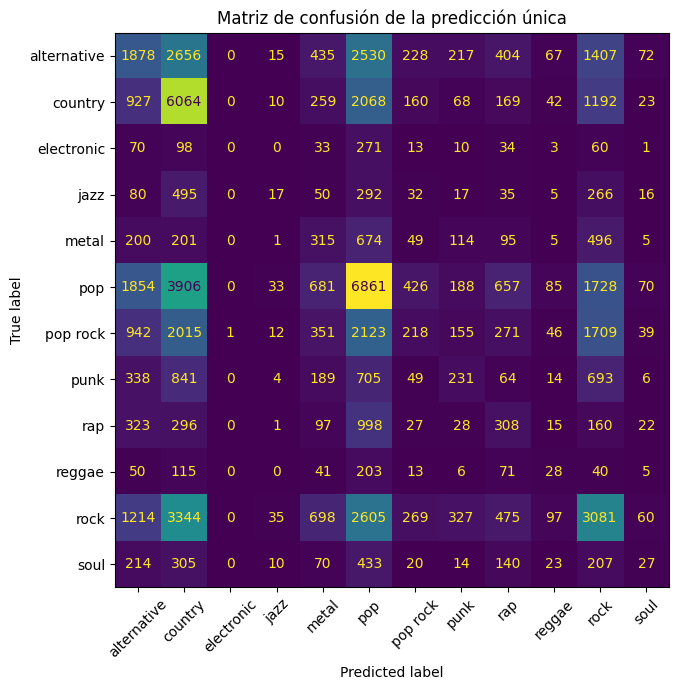

In [14]:
# USA_TEST: lectura de la misma predicción. No llama a predict ni a fit.
if "y_pred" not in globals():
    raise RuntimeError("Falta la predicción única. Ejecuta antes la celda de selección.")

report = classification_report(
    y_test,
    y_pred,
    labels=LABELS,
    output_dict=True,
    zero_division=0,
)
per_class = (
    pd.DataFrame(report)
    .T.loc[LABELS, ["precision", "recall", "f1-score", "support"]]
    .sort_values("f1-score")
)
per_class["support"] = per_class["support"].astype(int)
for column in ("precision", "recall", "f1-score"):
    per_class[column] = per_class[column].map(lambda value: round(float(value), 4))

cm = confusion_matrix(y_test, y_pred, labels=LABELS)
block = ("pop", "rock", "pop rock", "alternative", "punk")
inside = 0
total_errors = 0
pairs = []
for i, true_label in enumerate(LABELS):
    for j, pred_label in enumerate(LABELS):
        if i == j:
            continue
        count = int(cm[i, j])
        if count == 0:
            continue
        total_errors += count
        pairs.append((count, true_label, pred_label))
        if true_label in block and pred_label in block:
            inside += count
pairs.sort(reverse=True)

print("F1 por clase, de peor a mejor:")
print(per_class.to_string())
print(f"Errores fuera de la diagonal: {total_errors:,}")
if total_errors:
    print(
        f"Errores dentro de pop / rock / pop rock / alternative / punk: "
        f"{inside:,} ({inside / total_errors:.1%})"
    )
print("Confusiones más frecuentes (real → predicho):")
for count, true_label, pred_label in pairs[:10]:
    print(f"{count:6d}  {true_label} → {pred_label}")

fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=LABELS).plot(
    ax=ax,
    xticks_rotation=45,
    colorbar=False,
)
ax.set_title("Matriz de confusión de la predicción única")
fig.tight_layout()


## 12. Cierre

La celda de selección imprime qué pipeline quedó, su media y su desviación en validación, si el ajuste de SGD superó la variación del inicial, y el macro-F1 de la predicción única. La celda de errores imprime las clases peores y la fracción de confusiones dentro del bloque pop/rock.

Esa lectura cierra la pregunta de la asignación: qué modelo generaliza en este corte, y por qué la elección se sostiene cuando la diferencia entre candidatos es más chica que la variación entre artistas. El número de test describe ese pipeline. No autoriza a volver, cambiar la representación y predecir otra vez.


In [ ]:
import joblib, pandas as pd

model = joblib.load("../model.joblib")

songs = {
    "I-bVII-IV rock (D C G)":
        "<verse_1> D C G D D C G D <chorus_1> G C D G G C D G",
    "12-bar blues rock (E)":
        "<verse_1> E E E E A A E E B A E B",
    "power chords, hard rock (E5)":
        "<verse_1> E5 G5 A5 E5 E5 G5 A5 C5 <chorus_1> E5 D5 A5 A5",
}

new = pd.DataFrame({"chords": list(songs.values())})
for name, pred in zip(songs, model.predict(new)):
    print(f"{name:35s} -> {pred}")


I-bVII-IV rock (D C G)              -> country
12-bar blues rock (E)               -> rock
power chords, hard rock (E5)        -> alternative


: 